> **Historical CS data:** This notebook was generated before the IEEE39 FMU added checkpoint support and used single-pass explicit coupling. Its CS curves are superseded by `IEEE39_RollbackNewton_Validation.ipynb`; native and ME results remain useful as historical measurements.

# IEEE39 DPsim inverter comparison: native, FMI ME, and FMI CS

This notebook compares three fresh, closed-loop DPsim runs of the same IEEE39 EMT network. The averaged inverter is at bus 30, the network starts from the case powerflow, and a 100 MW load is switched onto bus 39 at 5 s. Each method runs for 10 s at the same communication/network timestep. Native DPsim is the error baseline for ME and CS at each matching timestep.

The native averaged inverter uses the same P/Q target, current limit, passive current sign, and 5 ms current response as the dual-interface FMU. Its initial current state is set to the FMU's start behavior (the P/Q reference evaluated at the solved powerflow voltage). Errors are computed from full-resolution run logs before those large files are discarded; compact plotting traces are retained. The 10–1000 µs data completed with an earlier two-iteration ME ceiling. The 5 ms ME case failed its residual check at that ceiling and was rerun with residual-based Newton using the default 20-iteration ceiling. The reproduction runner now uses that residual-based setting throughout.

**Regenerate runs** from the repository root with `python3 -u dpsim-fmi/examples/ieee39_inverter/run_ieee39_dpsim_native_me_cs_sweep.py`. The sweep includes 10, 25, 50, 100, 500, 1000, and 5000 µs; 5000 µs is shown as a coarse stress case. The notebook only reads saved metrics and traces.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "dpsim-fmi").is_dir():
    root = root.parent
if not (root / "dpsim-fmi").is_dir():
    raise FileNotFoundError("Open this notebook from a DPsim checkout")
results_dir = (
    root / "build-fmi" / "ieee39-inverter" / "dpsim-native-me-cs-10s-nosubcomponents"
)
metrics_path = results_dir / "metrics.json"
metrics = json.loads(metrics_path.read_text())
print(f"Results: {metrics_path}")
print(metrics["configuration"])

Results: /home/matthiasmees/dpsim/build-fmi/ieee39-inverter/dpsim-native-me-cs-10s-nosubcomponents/metrics.json
{'grid': 'IEEE39_Ph3 EMT network, inverter at bus 30', 'dynamic_network_components': 'Conventional PiLines, RX loads, and transformers with subcomponents disabled; conventional VBR SG4 generators', 'duration_s': 10.0, 'load_step_s': 5.0, 'load_step_MW': 100, 'steps_us': [10, 25, 50, 100, 500, 1000, 5000], 'methods': ['native', 'me', 'cs'], 'initialization': 'same solved IEEE39 powerflow; native and FMU initial inverter current match at t=0', 'rolling_error_window_s': 0.1, 'error_reference': 'native DPsim at matching timestep', 'ME_newton_stopping': 'residual-based; current source default ceiling 20'}


## Full-run errors and timing

,timestep [µs],method,PCC voltage RMS error [%],inverter current RMS error [%],solver wall [s],process wall [s]
2,10,CS,0.0104,0.19624,654.05,654.69
1,10,ME,5.6549e-10,1.6769e-08,782.37,783.01
0,10,NATIVE,—,—,708.85,709.47
5,25,CS,0.026002,0.49065,261.96,262.22
4,25,ME,2.5238e-10,1.085e-08,313.27,313.53
3,25,NATIVE,—,—,281.17,281.43
8,50,CS,0.052011,0.98148,131.39,131.53
7,50,ME,2.0331e-10,8.4444e-09,156.74,156.88
6,50,NATIVE,—,—,141.18,141.32
11,100,CS,0.10405,1.9638,65.768,65.846


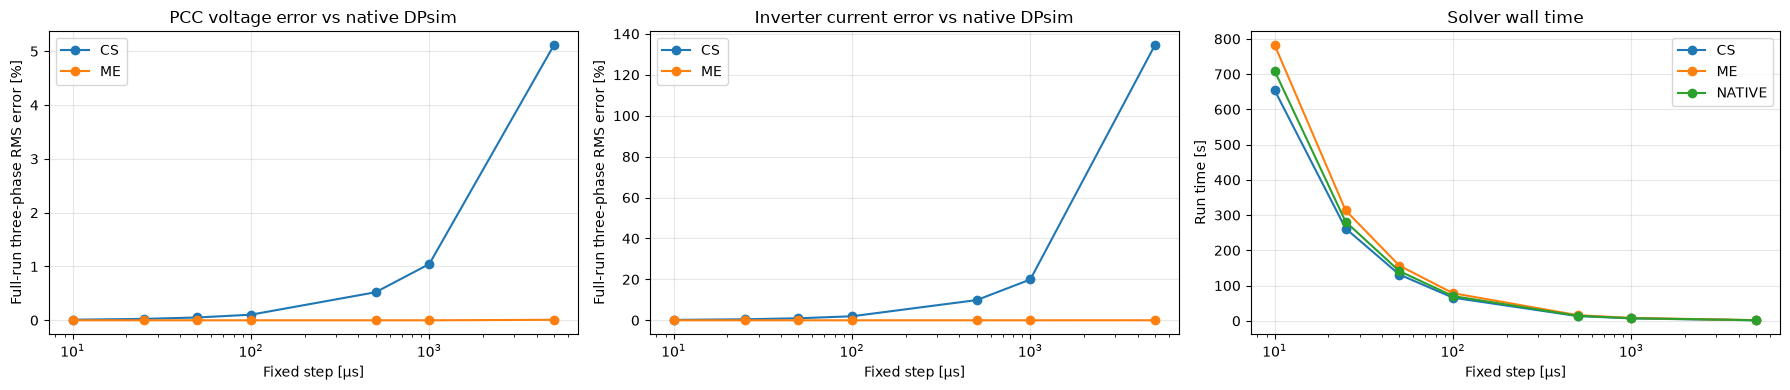

In [2]:
rows = []
for step, case in metrics["cases"].items():
    for method in ("native", "me", "cs"):
        r = case["runtimes"][method]
        comp = case["comparisons"].get(method)
        s = comp["full_run"] if comp else {}
        rows.append(
            {
                "timestep [µs]": int(step),
                "method": method.upper(),
                "PCC voltage RMS error [%]": s.get("voltage_rms_error_percent"),
                "inverter current RMS error [%]": s.get("current_rms_error_percent"),
                "solver wall [s]": r["solver_wall_s"],
                "process wall [s]": r["process_wall_s"],
            }
        )
summary = pd.DataFrame(rows).sort_values(["timestep [µs]", "method"])
display(
    summary.style.format(
        {c: "{:.5g}" for c in summary.select_dtypes("number").columns}, na_rep="—"
    )
)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for method, group in summary.groupby("method"):
    if method != "NATIVE":
        ax[0].plot(
            group["timestep [µs]"],
            group["PCC voltage RMS error [%]"],
            "o-",
            label=method,
        )
        ax[1].plot(
            group["timestep [µs]"],
            group["inverter current RMS error [%]"],
            "o-",
            label=method,
        )
    ax[2].plot(group["timestep [µs]"], group["solver wall [s]"], "o-", label=method)
for a, title, ylabel in zip(
    ax,
    [
        "PCC voltage error vs native DPsim",
        "Inverter current error vs native DPsim",
        "Solver wall time",
    ],
    [
        "Full-run three-phase RMS error [%]",
        "Full-run three-phase RMS error [%]",
        "Run time [s]",
    ],
):
    a.set_xscale("log")
    a.set_xlabel("Fixed step [µs]")
    a.set_ylabel(ylabel)
    a.set_title(title)
    a.grid(True, alpha=0.3)
    a.legend()
plt.tight_layout()

## Initialization check

In [3]:
init_rows = []
for step, case in metrics["cases"].items():
    for method, comp in case["comparisons"].items():
        x = comp["initial"]
        init_rows.append(
            {
                "step [µs]": int(step),
                "method": method.upper(),
                "native Vabc at t=0 [V]": x["native_v_abc_V"],
                "candidate Vabc at t=0 [V]": x["candidate_v_abc_V"],
                "native Iabc at t=0 [A]": x["native_i_abc_A"],
                "candidate Iabc at t=0 [A]": x["candidate_i_abc_A"],
            }
        )
display(pd.DataFrame(init_rows))

,step [µs],method,native Vabc at t=0 [V],candidate Vabc at t=0 [V],native Iabc at t=0 [A],candidate Iabc at t=0 [A]
0,10,ME,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
1,10,CS,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
2,25,ME,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
3,25,CS,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
4,50,ME,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
5,50,CS,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
6,100,ME,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
7,100,CS,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
8,500,ME,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"
9,500,CS,"[288466.352188, -200716.863664, -87749.488524]","[288466.352188, -200716.863664, -87749.488524]","[-234.627119, 325.134235, -90.507115]","[-234.627119, 325.134235, -90.507115]"


## Per-timestep error traces and load-step response

For every timestep, the first figure shows the trailing 100 ms three-phase RMS error. The second shows cumulative RMS error from time zero through each point, estimated from the retained compact traces; the full-run summary above uses full-resolution data. The lower waveform figure zooms to ±25 ms around the 5 s event and overlays phase-a PCC voltage and inverter current for all three methods.

### 10 µs


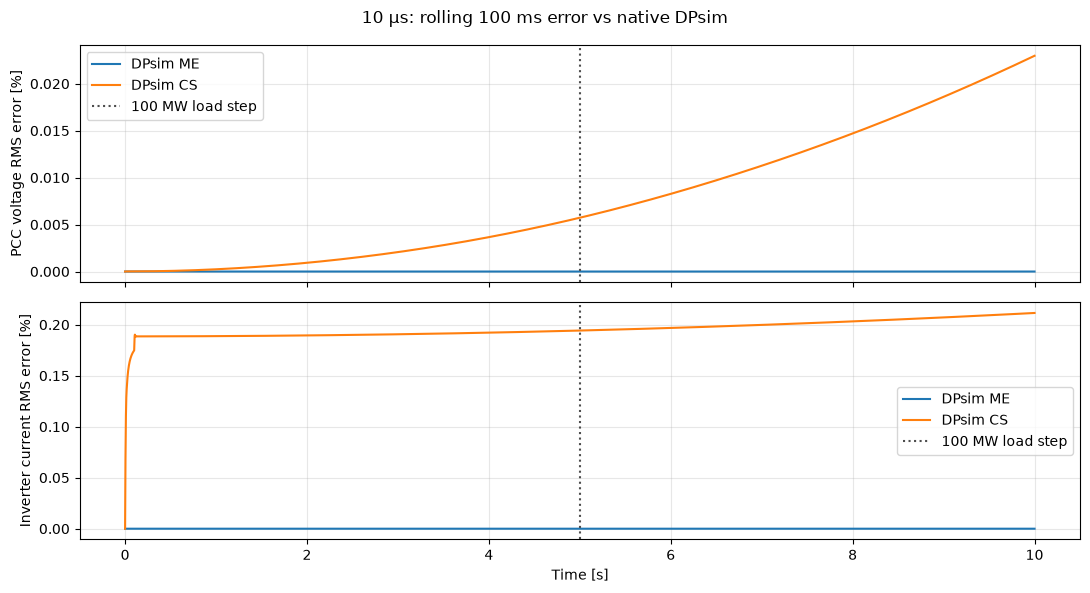

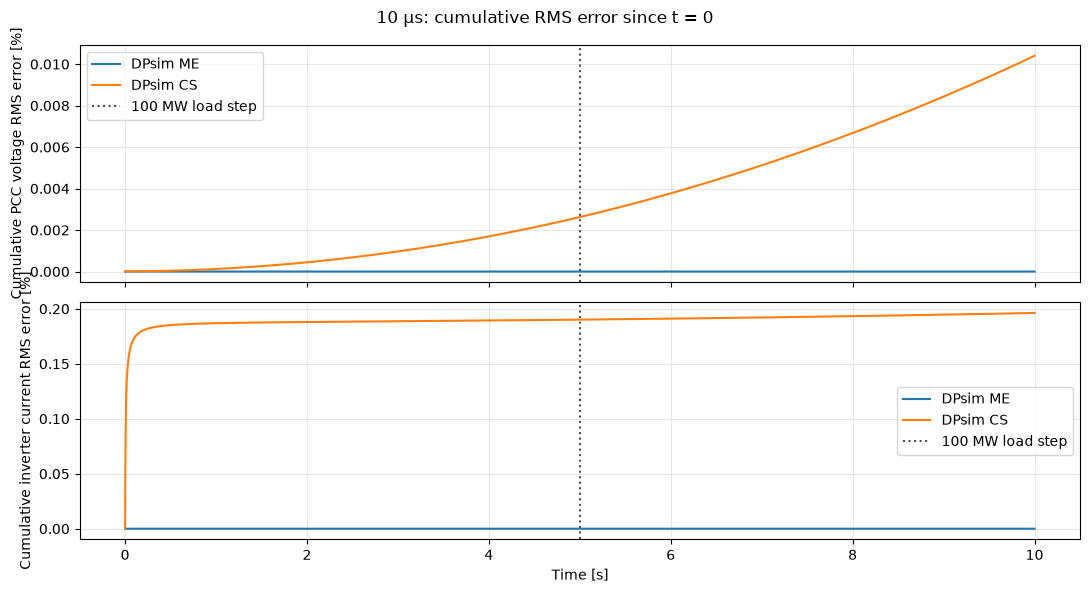

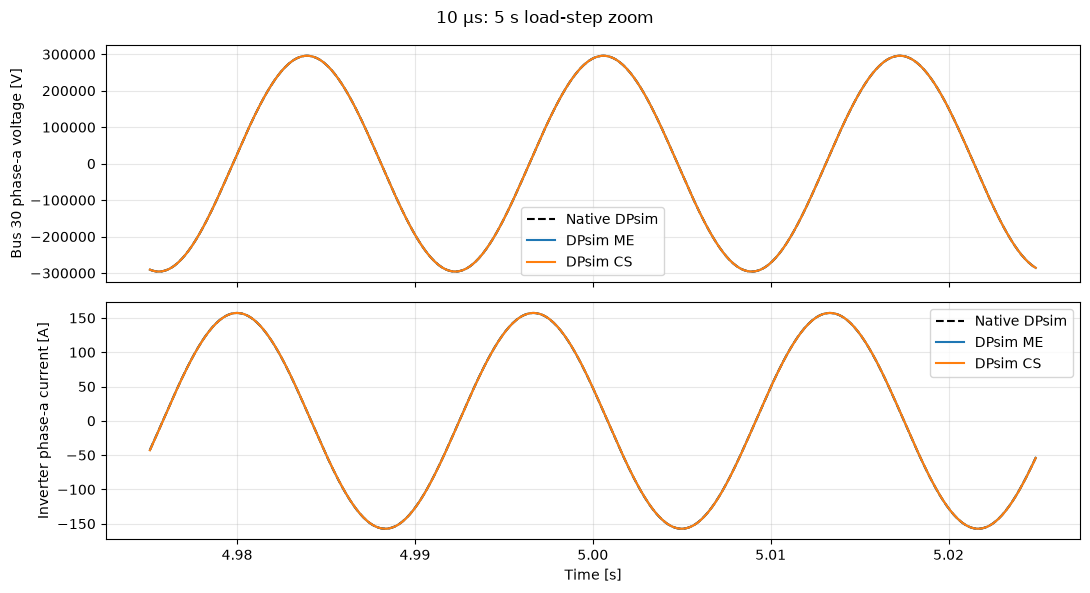

### 25 µs


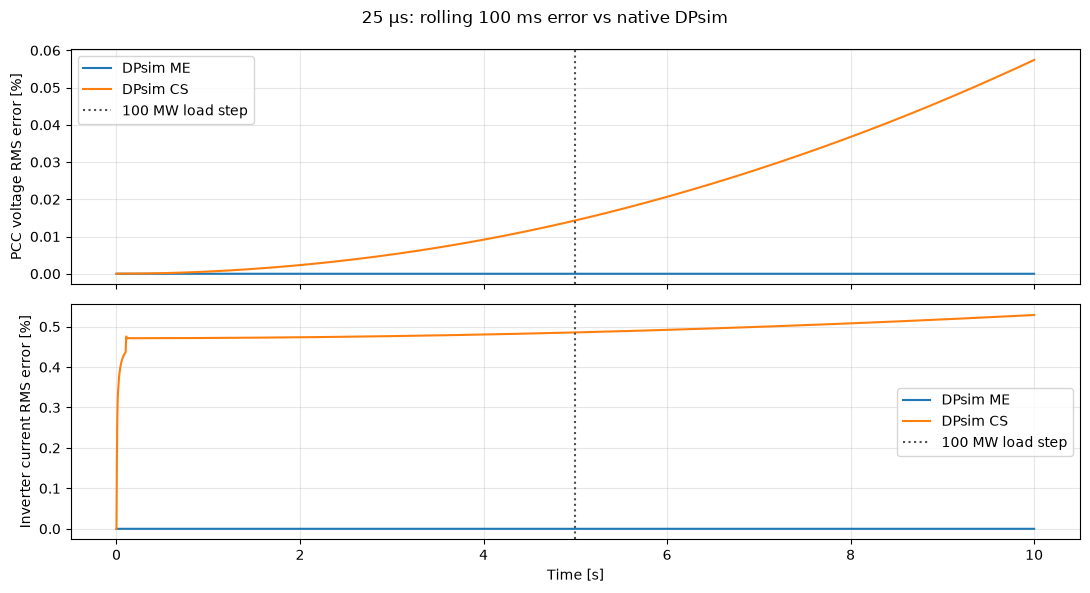

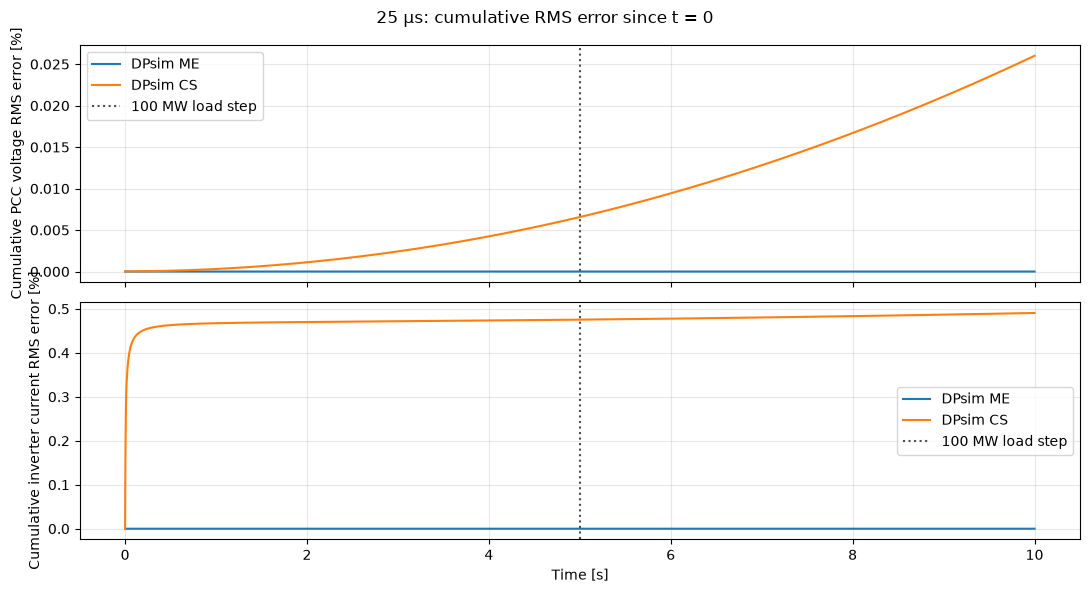

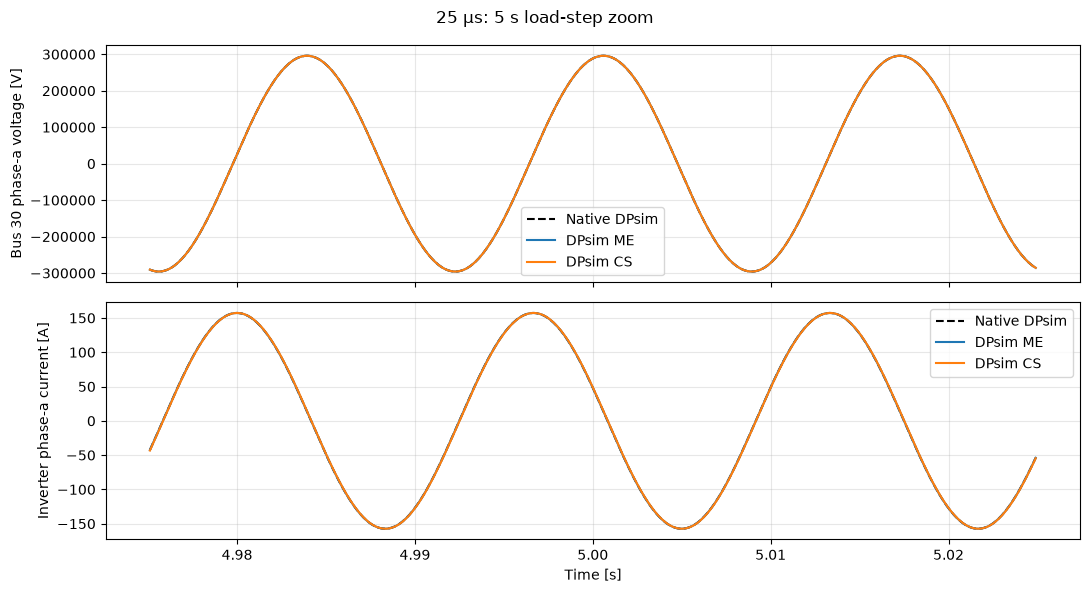

### 50 µs


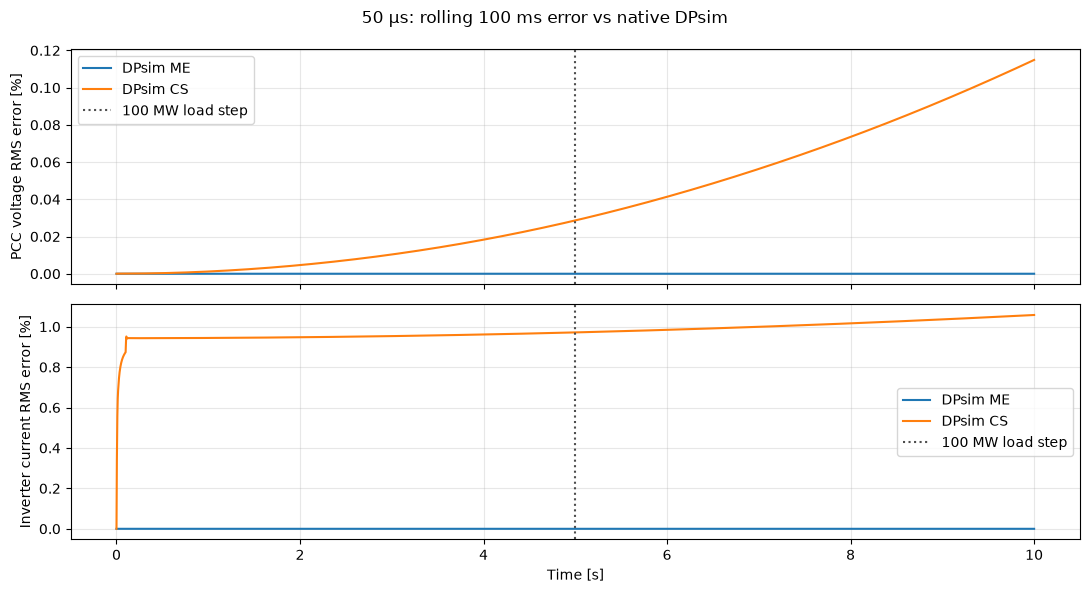

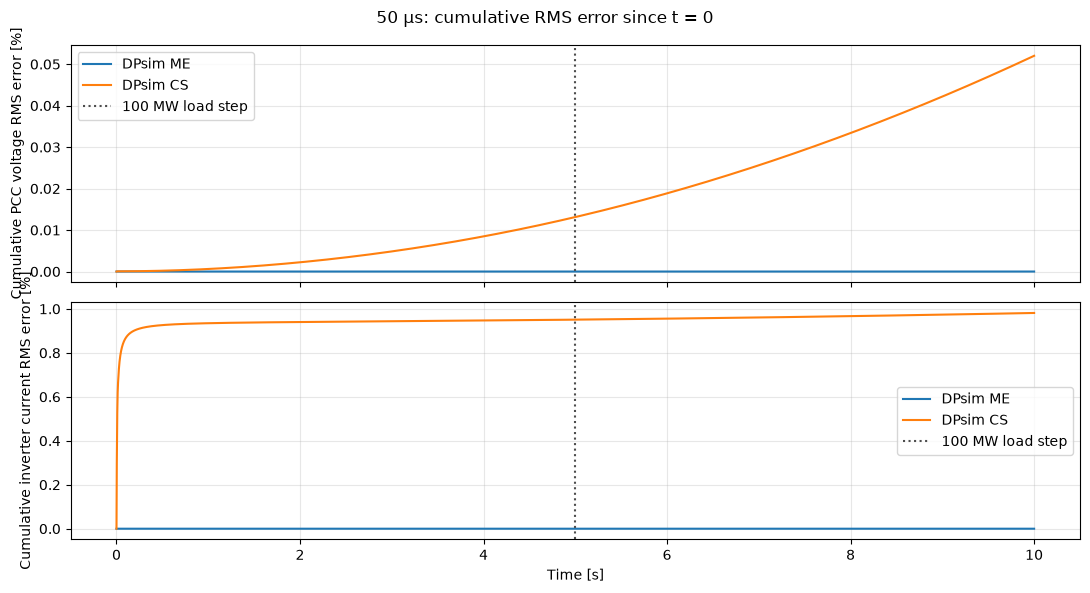

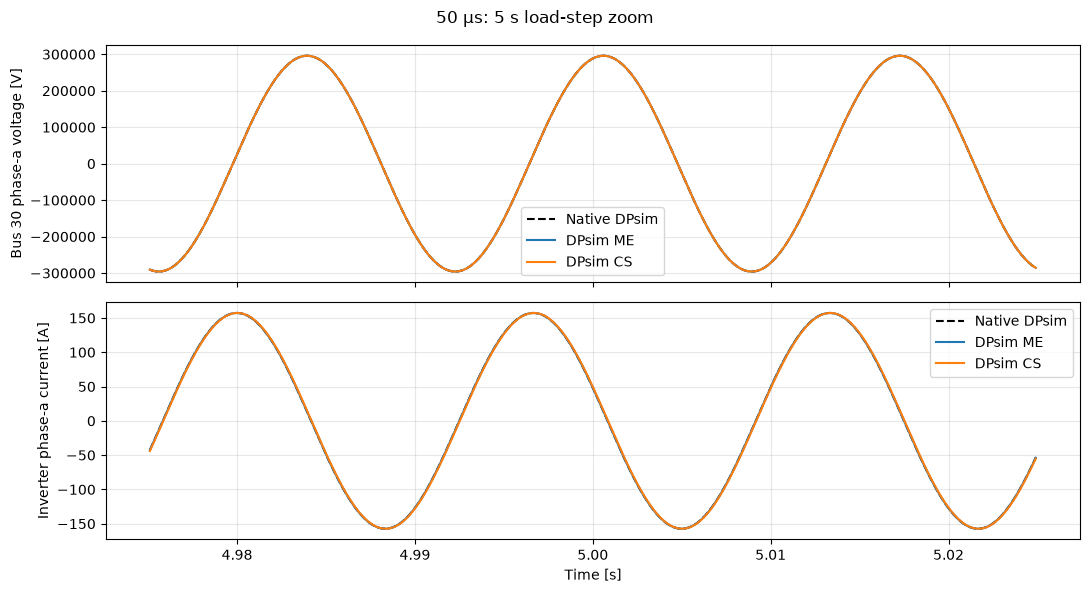

### 100 µs


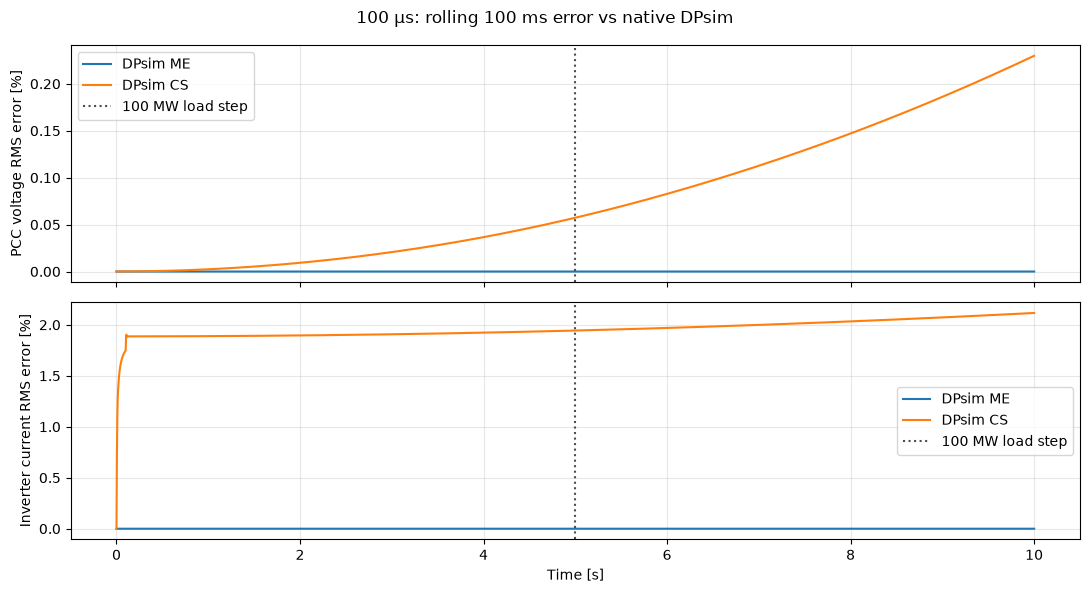

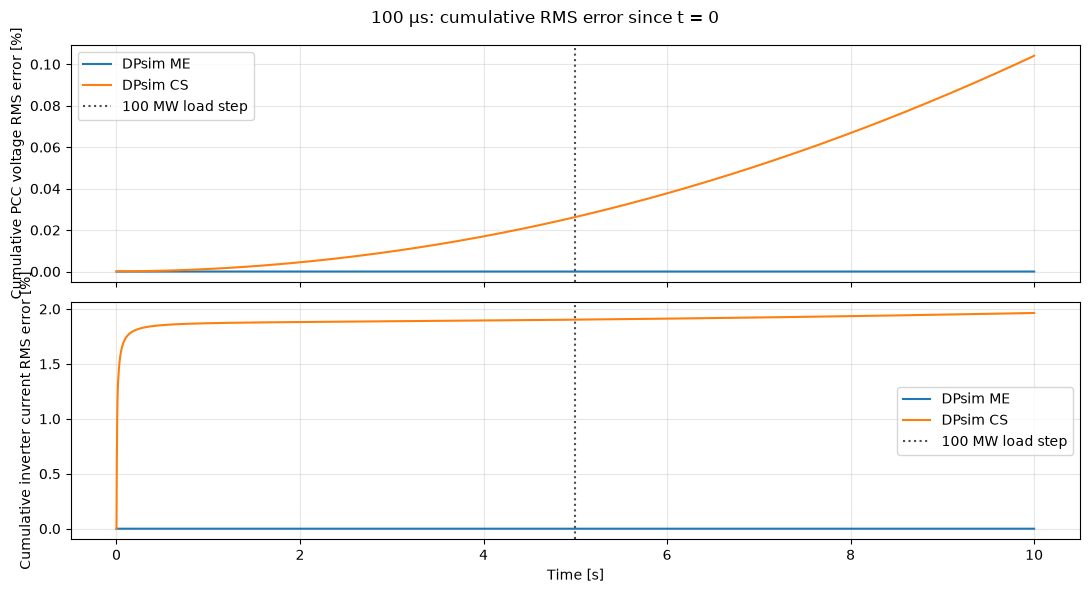

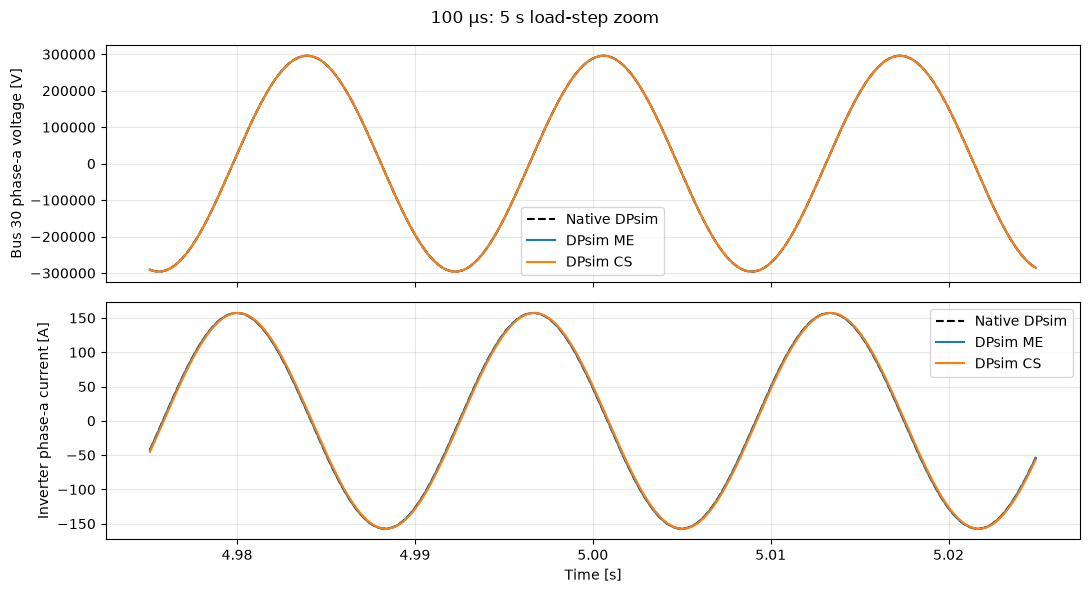

### 500 µs


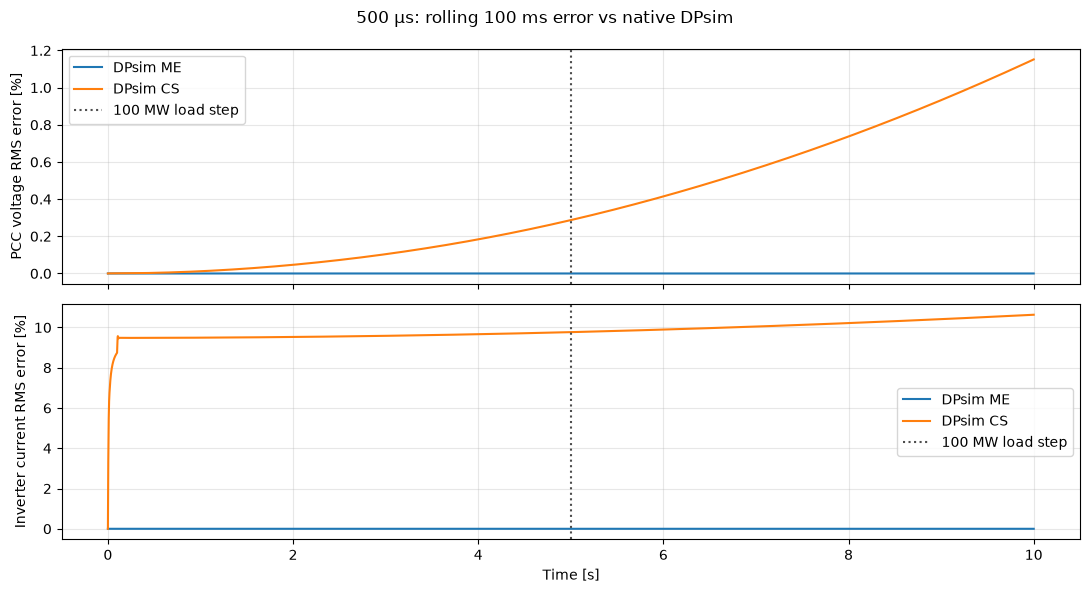

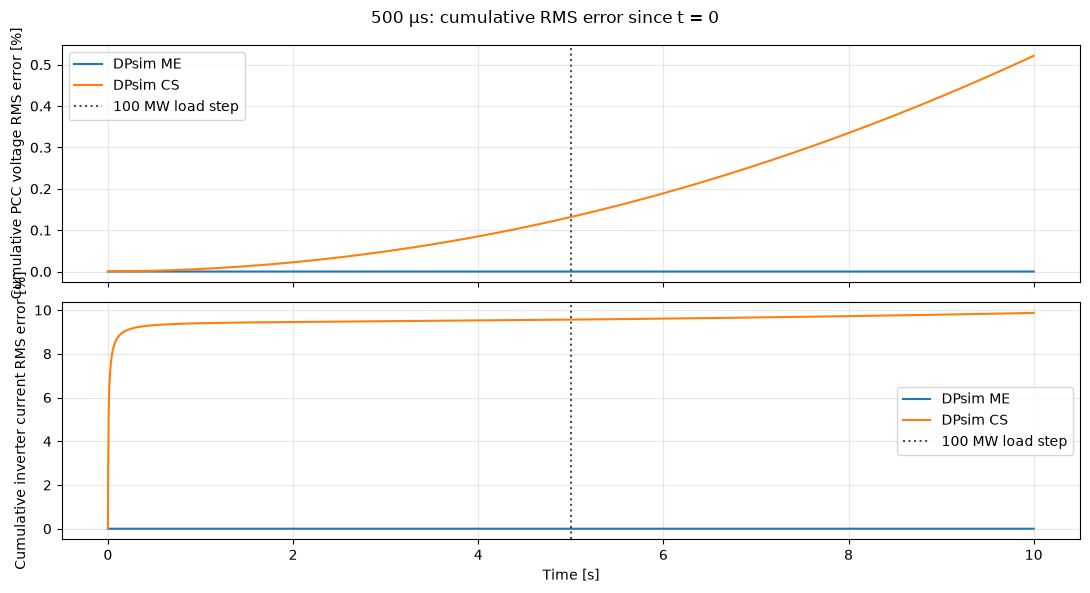

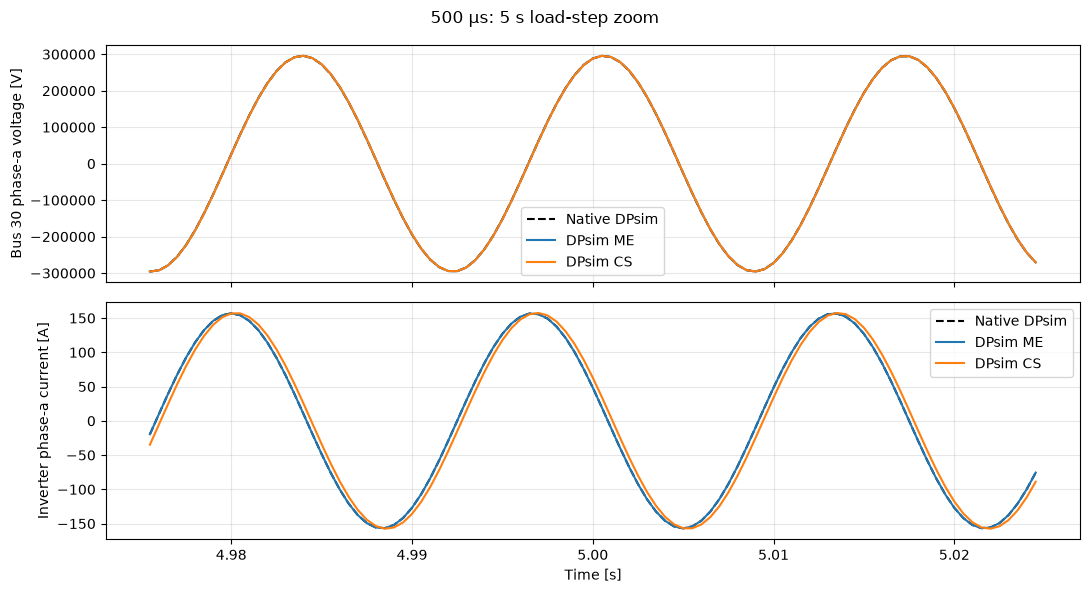

### 1000 µs


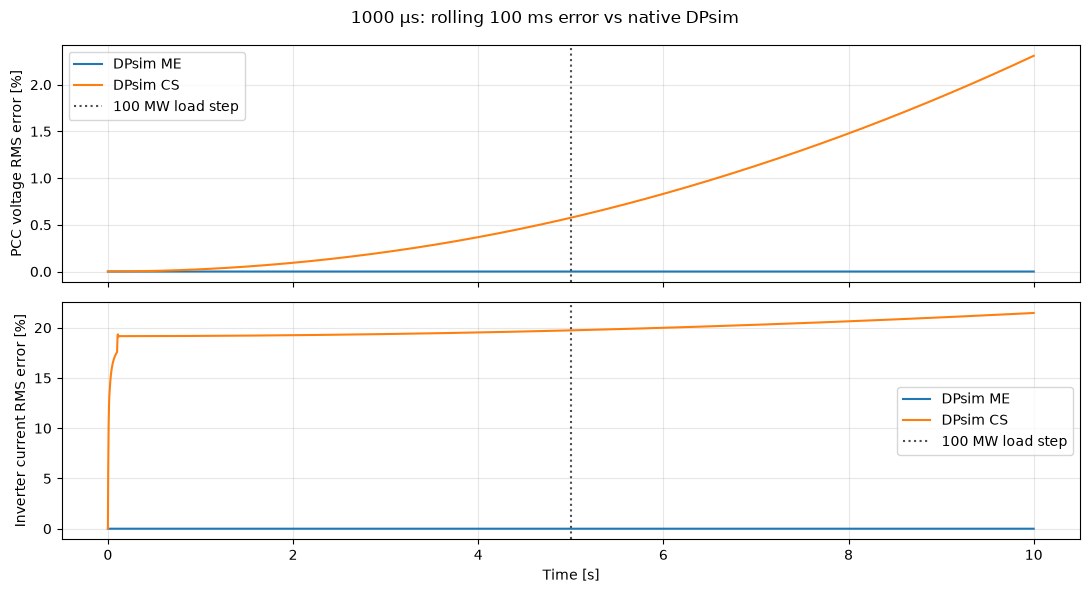

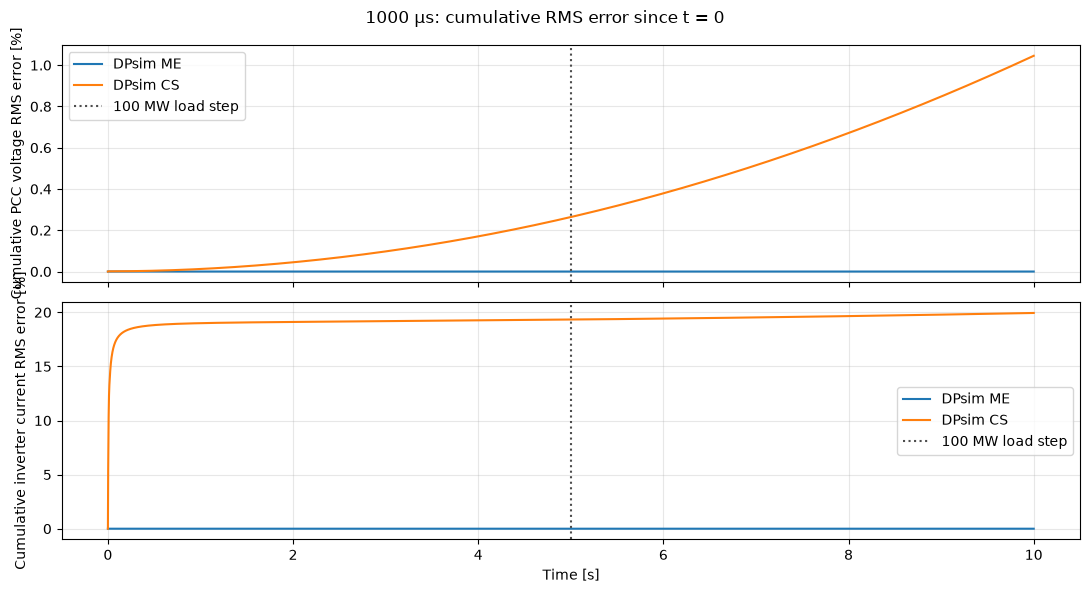

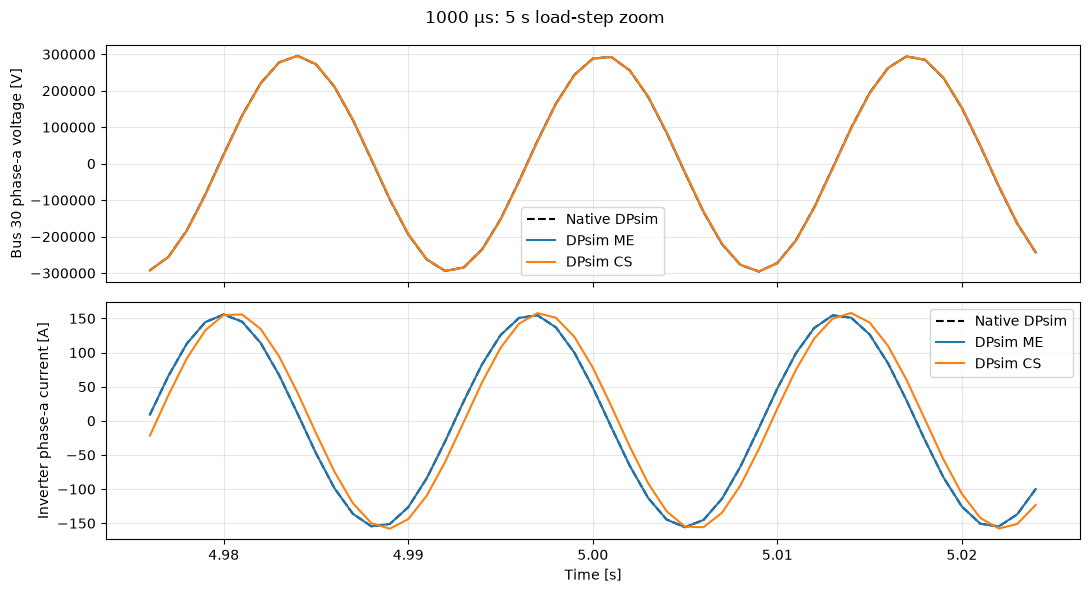

### 5000 µs


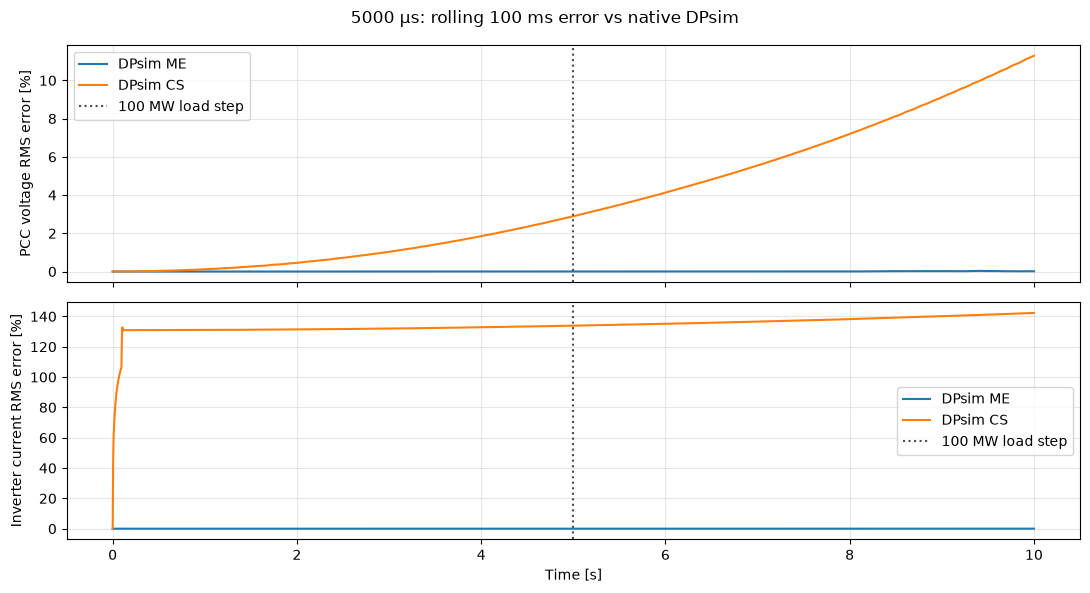

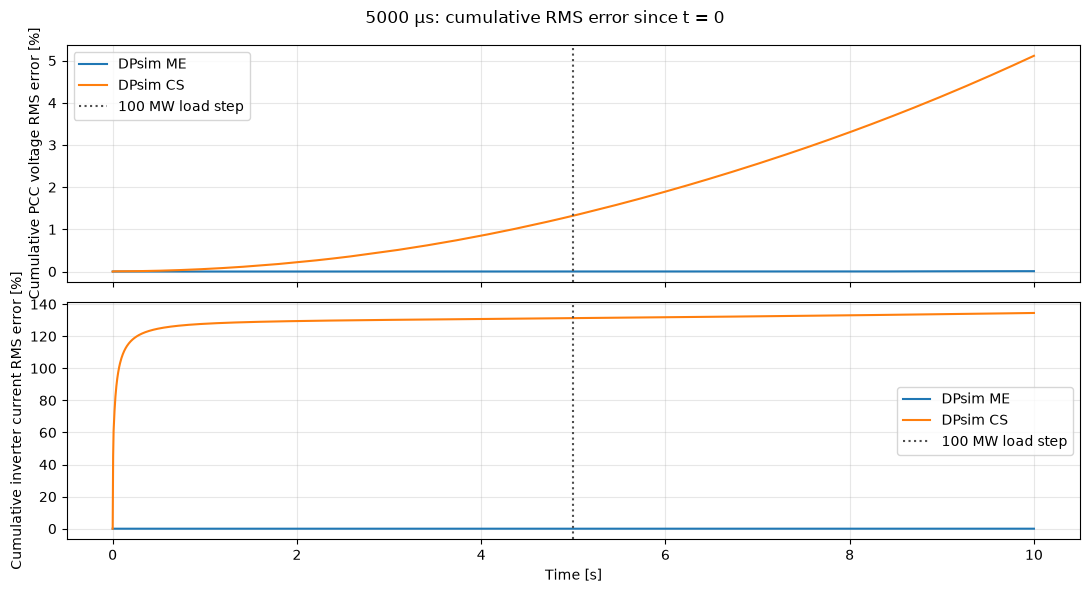

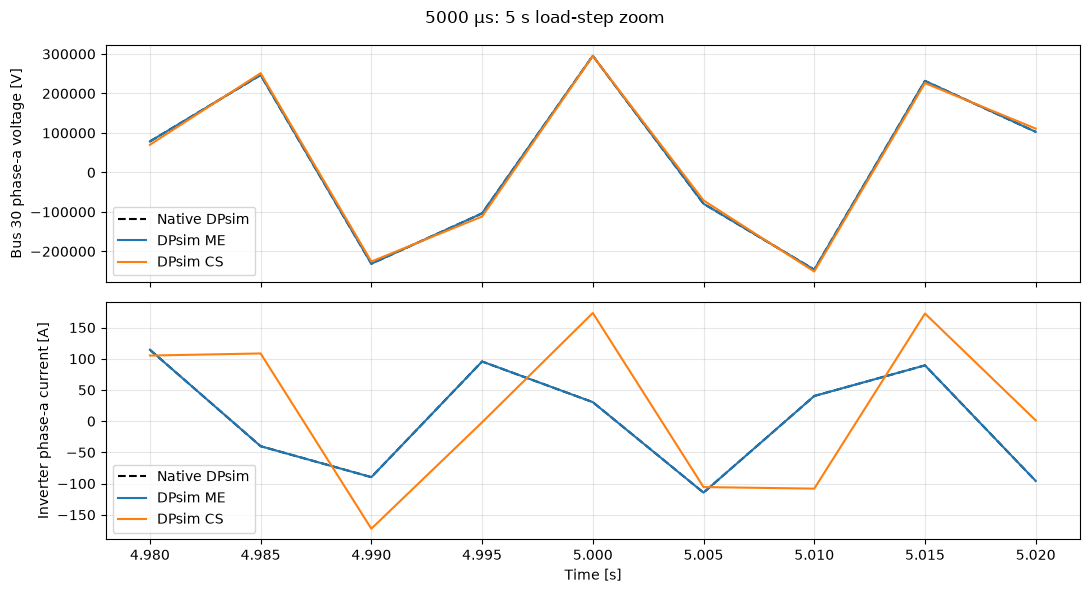

In [4]:
for step, case in sorted(metrics["cases"].items(), key=lambda item: int(item[0])):
    step = int(step)
    print(f"### {step} µs")
    me = case["comparisons"]["me"]
    cs = case["comparisons"]["cs"]
    em = pd.read_csv(me["rolling_error_trace"])
    ec = pd.read_csv(cs["rolling_error_trace"])
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    for frame, label in [(em, "DPsim ME"), (ec, "DPsim CS")]:
        ax[0].plot(frame.time_s, frame.pcc_voltage_rms_error_percent_100ms, label=label)
        ax[1].plot(
            frame.time_s, frame.inverter_current_rms_error_percent_100ms, label=label
        )
    ax[0].set_ylabel("PCC voltage RMS error [%]")
    ax[1].set_ylabel("Inverter current RMS error [%]")
    ax[1].set_xlabel("Time [s]")
    for a in ax:
        a.axvline(5, color="0.3", ls=":", label="100 MW load step")
        a.grid(True, alpha=0.3)
        a.legend()
    fig.suptitle(f"{step} µs: rolling 100 ms error vs native DPsim")
    plt.tight_layout()
    plt.show()

    native_path = case["runtimes"]["native"]["directory"] + "/native_trace.csv"
    native = pd.read_csv(native_path)
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    for mode, label in (("me", "DPsim ME"), ("cs", "DPsim CS")):
        candidate = pd.read_csv(case["comparisons"][mode]["compact_trace"])
        if len(candidate) != len(native) or not np.allclose(
            candidate.time_s, native.time_s, rtol=0, atol=1e-12
        ):
            raise ValueError(
                f"{step} µs {label} compact trace does not align with native DPsim"
            )
        vcols = ["pcc_v_a_V", "pcc_v_b_V", "pcc_v_c_V"]
        icols = ["current_a_A", "current_b_A", "current_c_A"]
        vdiff = (candidate[vcols].to_numpy() - native[vcols].to_numpy()) ** 2
        idiff = (candidate[icols].to_numpy() - native[icols].to_numpy()) ** 2
        vref = native[vcols].to_numpy() ** 2
        iref = native[icols].to_numpy() ** 2
        verror = 100 * np.sqrt(
            np.cumsum(vdiff.sum(axis=1)) / np.cumsum(vref.sum(axis=1))
        )
        ierror = 100 * np.sqrt(
            np.cumsum(idiff.sum(axis=1)) / np.cumsum(iref.sum(axis=1))
        )
        ax[0].plot(native.time_s, verror, label=label)
        ax[1].plot(native.time_s, ierror, label=label)
    ax[0].set_ylabel("Cumulative PCC voltage RMS error [%]")
    ax[1].set_ylabel("Cumulative inverter current RMS error [%]")
    ax[1].set_xlabel("Time [s]")
    for a in ax:
        a.axvline(5, color="0.3", ls=":", label="100 MW load step")
        a.grid(True, alpha=0.3)
        a.legend()
    fig.suptitle(f"{step} µs: cumulative RMS error since t = 0")
    plt.tight_layout()
    plt.show()

    zm = pd.read_csv(me["load_step_zoom_trace"])
    zc = pd.read_csv(cs["load_step_zoom_trace"])
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    ax[0].plot(zm.time_s, zm.native_v_a_V, "k--", label="Native DPsim")
    ax[0].plot(zm.time_s, zm.me_v_a_V, label="DPsim ME")
    ax[0].plot(zc.time_s, zc.cs_v_a_V, label="DPsim CS")
    ax[1].plot(zm.time_s, zm.native_i_a_A, "k--", label="Native DPsim")
    ax[1].plot(zm.time_s, zm.me_i_a_A, label="DPsim ME")
    ax[1].plot(zc.time_s, zc.cs_i_a_A, label="DPsim CS")
    ax[0].set_ylabel("Bus 30 phase-a voltage [V]")
    ax[1].set_ylabel("Inverter phase-a current [A]")
    ax[1].set_xlabel("Time [s]")
    for a in ax:
        a.grid(True, alpha=0.3)
        a.legend()
    fig.suptitle(f"{step} µs: 5 s load-step zoom")
    plt.tight_layout()
    plt.show()

## Interpretation notes

Each timestep is a separate comparison and uses the native DPsim run at that same timestep as its baseline. The percentages describe implementation agreement at a matched discretization, not absolute physical accuracy. A coarse timestep changes the discrete-time network and inverter trajectories for all three methods. The 5000 µs result is a coarse-step stress test; interpret it separately from the 10–1000 µs sweep.